# Training – ajuste y selección de modelos

Imputación de datos, selección de variables y comparación de modelos: regresión lineal (OLS), GLM Gamma, GAM (normal y gamma) y modelos de machine learning (ElasticNet, Random Forest y Gradient Boosting).

## Lectura de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"../data/Food_Delivery_Times.csv")

target = "Delivery_Time_min"
numericas = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs"]
categoricas = ["Weather", "Traffic_Level", "Time_of_Day", "Vehicle_Type"]


## 1. Separación train/test, imputación y función de evaluación

La imputación (mediana para numéricas, moda para categóricas) se aprende solo con train y se aplica a validación/test.

In [2]:
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Categoricas
df[categoricas] = df[categoricas].astype(object)

# =========================================================
# Separar train / test (test solo se usa al final)
# =========================================================
train, test = train_test_split(df, test_size=0.2, random_state=17)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)

# =========================================================
#  Imputación
# =========================================================
def ajustar_imputador(d):
    """Devuelve mediana (numéricas) y moda (categóricas) calculadas en d."""
    return {**d[numericas].median().to_dict(),
            **d[categoricas].mode().iloc[0].to_dict()}

def imputar(d, valores):
    return d.fillna(value=valores)

# =========================================================
# Evaluación de un modelo: CV + métricas in-sample
# =========================================================
def evaluar(terminos, datos, n_splits=10, seed=17):
    formula = f"{target} ~ " + (" + ".join(terminos) if terminos else "1")
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    mae, rmse, r2, mape = [], [], [], []

    for idx_tr, idx_va in kf.split(datos):
        tr, va = datos.iloc[idx_tr], datos.iloc[idx_va]
        vals = ajustar_imputador(tr)              # se aprende SOLO con el fold de train
        tr, va = imputar(tr, vals), imputar(va, vals)

        m = smf.ols(formula, data=tr).fit()
        pred = m.predict(va)
        mae.append(mean_absolute_error(va[target], pred))
        rmse.append(np.sqrt(mean_squared_error(va[target], pred)))
        mape.append(np.mean(np.abs((va[target] - pred) / va[target])) * 100)
        r2.append(r2_score(va[target], pred))

    # Ajuste con train: R2 ajustado, AIC, BIC
    full = imputar(datos, ajustar_imputador(datos))
    m = smf.ols(formula, data=full).fit()

    return {
        "formula": formula,
        "n_param": int(m.df_model) + 1,
        "MAE_cv": np.mean(mae),  "MAE_sd": np.std(mae),
        "RMSE_cv": np.mean(rmse), "RMSE_sd": np.std(rmse),
        "MAPE_cv": np.mean(mape), "MAPE_sd": np.std(mape),
        "R2_cv": np.mean(r2),
        "R2_adj": m.rsquared_adj,
        "AIC": m.aic,
        "BIC": m.bic,
    }

cols_metricas = ["n_param", "MAE_cv", "MAE_sd", "RMSE_cv", "RMSE_sd", "MAPE_cv", "MAPE_sd", "R2_cv", "R2_adj", "AIC", "BIC"]

## 2. Regresión lineal (OLS)

### Modelos definidos a mano

In [3]:
# =========================================================
# Comparación de modelos definidos a mano
# =========================================================
principales = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs",
               "C(Weather)", "C(Traffic_Level)", "C(Time_of_Day)", "C(Vehicle_Type)"]

modelos = {
    "M0 Solo intercepto":          [],
    "M1 Simple (Distancia)":       ["Distance_km"],
    "M2 Solo numéricas":           numericas,
    "M3 Efectos principales":      principales,
    "M4 M3 + Distancia×Tráfico":   principales + ["Distance_km:C(Traffic_Level)"],
    "M5 M3 + Distancia×Clima":     principales + ["Distance_km:C(Weather)"],
    "M6 M3 + Distancia×Vehículo":  principales + ["Distance_km:C(Vehicle_Type)"],
    "M7 M3 + Tráfico×Clima":       principales + ["C(Traffic_Level):C(Weather)"],
    "M8 M3 + Experiencia×Tráfico": principales + ["Courier_Experience_yrs:C(Traffic_Level)"],
    "M9 M3 + Distancia×Preparación":     principales + ["Distance_km:Preparation_Time_min"],
}

comparacion = pd.DataFrame({nombre: evaluar(t, train) for nombre, t in modelos.items()}).T
print("=== Comparación de modelos (CV 10 folds sobre train) ===")
print(comparacion[cols_metricas].astype(float).round(3).sort_values("RMSE_cv").to_string())

=== Comparación de modelos (CV 10 folds sobre train) ===
                               n_param  MAE_cv  MAE_sd  RMSE_cv  RMSE_sd  MAPE_cv  MAPE_sd  R2_cv  R2_adj       AIC       BIC
M3 Efectos principales            15.0   6.669   0.961   10.686    2.027   11.097    1.167  0.758   0.764  6086.093  6156.362
M5 M3 + Distancia×Clima           19.0   6.700   1.031   10.689    2.023   11.145    1.260  0.758   0.764  6089.483  6178.491
M4 M3 + Distancia×Tráfico         17.0   6.687   0.970   10.692    2.030   11.126    1.151  0.758   0.764  6088.392  6168.031
M9 M3 + Distancia×Preparación     16.0   6.685   0.974   10.703    2.038   11.139    1.193  0.757   0.764  6088.022  6162.976
M6 M3 + Distancia×Vehículo        17.0   6.691   0.930   10.714    1.993   11.142    1.122  0.757   0.764  6087.790  6167.428
M8 M3 + Experiencia×Tráfico       17.0   6.700   0.946   10.718    2.029   11.169    1.116  0.757   0.764  6087.789  6167.427
M7 M3 + Tráfico×Clima             23.0   6.773   0.965   10.7

In [ ]:
# Elegir el mejor modelo según RMSE_cv
mejor_nombre = comparacion["RMSE_cv"].astype(float).idxmin()
terminos_mejor = modelos[mejor_nombre]
formula_mejor = comparacion.loc[mejor_nombre, "formula"]
print(f"Mejor modelo: {mejor_nombre}")
print(f"Fórmula: {formula_mejor}\n")

# Reajustar con todo train 
vals = ajustar_imputador(train)
train_imp = imputar(train, vals)
modelo_mejor = smf.ols(formula_mejor, data=train_imp).fit()

# Resumen completo de statsmodels
print(modelo_mejor.summary())


Mejor modelo: M3 Efectos principales
Fórmula: Delivery_Time_min ~ Distance_km + Preparation_Time_min + Courier_Experience_yrs + C(Weather) + C(Traffic_Level) + C(Time_of_Day) + C(Vehicle_Type)

                            OLS Regression Results                            
Dep. Variable:      Delivery_Time_min   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.764
Method:                 Least Squares   F-statistic:                     185.8
Date:                Tue, 17 Nov 2026   Prob (F-statistic):          7.68e-238
Time:                        12:49:45   Log-Likelihood:                -3028.0
No. Observations:                 800   AIC:                             6086.
Df Residuals:                     785   BIC:                             6156.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                

### Selección forward con interacciones y evaluación en test


=== Selección forward con criterio RMSE_cv ===
 paso               agregado  n_param  MAE_cv  MAE_sd  RMSE_cv  RMSE_sd  MAPE_cv  MAPE_sd  R2_cv  R2_adj      AIC      BIC
    0           (intercepto)        1  17.894   1.109   22.099    1.685   41.353    3.399 -0.020   0.000 7227.434 7232.119
    1            Distance_km        2  10.226   0.676   13.848    1.558   20.753    1.960  0.595   0.607 6481.820 6491.190
    2   Preparation_Time_min        3   7.945   0.773   11.871    1.736   14.593    1.248  0.703   0.709 6242.333 6256.387
    3       C(Traffic_Level)        5   7.357   0.832   11.280    1.763   12.970    1.132  0.732   0.737 6163.832 6187.255
    4             C(Weather)        9   6.851   0.890   10.886    1.848   11.571    1.069  0.750   0.756 6105.792 6147.953
    5 Courier_Experience_yrs       10   6.626   0.896   10.680    1.970   10.964    1.071  0.758   0.764 6080.931 6127.778
Términos elegidos: ['Distance_km', 'Preparation_Time_min', 'C(Traffic_Level)', 'C(Weather)'

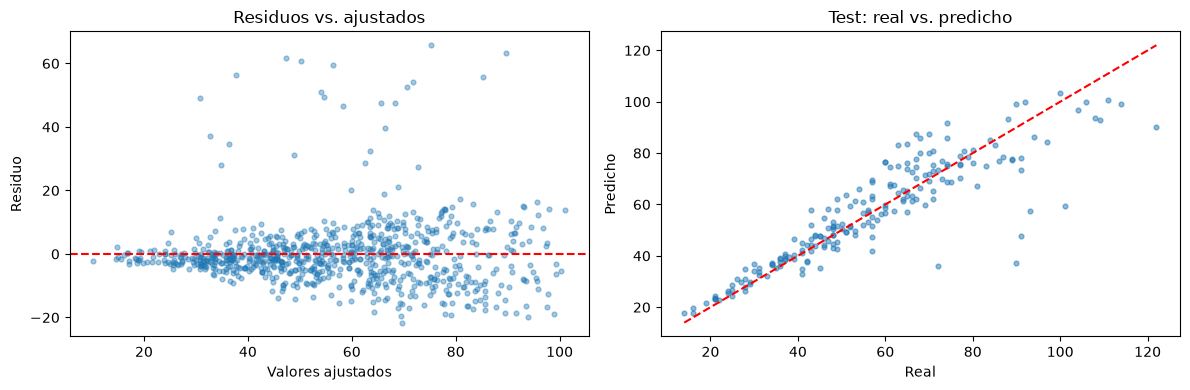

In [ ]:
interacciones = {
    "Distance_km:C(Traffic_Level)":            ["Distance_km", "C(Traffic_Level)"],
    "Distance_km:C(Weather)":                  ["Distance_km", "C(Weather)"],
    "Distance_km:C(Vehicle_Type)":             ["Distance_km", "C(Vehicle_Type)"],
    "Distance_km:C(Time_of_Day)":              ["Distance_km", "C(Time_of_Day)"],
    "Distance_km:Preparation_Time_min":        ["Distance_km", "Preparation_Time_min"],
    "Courier_Experience_yrs:C(Traffic_Level)": ["Courier_Experience_yrs", "C(Traffic_Level)"],
    "Courier_Experience_yrs:C(Vehicle_Type)":  ["Courier_Experience_yrs", "C(Vehicle_Type)"],
    "C(Traffic_Level):C(Weather)":             ["C(Traffic_Level)", "C(Weather)"],
}

MAYOR_ES_MEJOR = {"R2_adj", "R2_cv"}

def seleccion_forward(datos, criterio="RMSE_cv", tol=None):
    if tol is None:   # mejora mínima: evita agregar términos por ruido (igual que model_pipeline)
        tol = 0.01 if criterio in ("RMSE_cv", "MAE_cv", "MAPE_cv") else 0.0
    signo = -1 if criterio in MAYOR_ES_MEJOR else 1
    seleccion, historial = [], []
    actual = evaluar([], datos)
    historial.append({"paso": 0, "agregado": "(intercepto)", **actual})

    while True:
        candidatos = [t for t in principales if t not in seleccion] + \
                     [t for t, req in interacciones.items()
                      if t not in seleccion and all(r in seleccion for r in req)]
        if not candidatos:
            break

        resultados = [(t, evaluar(seleccion + [t], datos)) for t in candidatos]
        mejor_t, mejor = min(resultados, key=lambda x: signo * x[1][criterio])

        if signo * mejor[criterio] >= signo * actual[criterio] - tol:
            break
        seleccion.append(mejor_t)
        actual = mejor
        historial.append({"paso": len(seleccion), "agregado": mejor_t, **mejor})

    return seleccion, pd.DataFrame(historial)

# Ejecutar con cada criterio y guardar resultados
criterios = ["RMSE_cv", "MAPE_cv", "AIC", "BIC"]
resultados_sel = {}

for criterio in criterios:
    sel, hist = seleccion_forward(train, criterio=criterio)
    resultados_sel[criterio] = {"terminos": sel, "historial": hist}
    print(f"\n=== Selección forward con criterio {criterio} ===")
    print(hist[["paso", "agregado"] + cols_metricas].round(3).to_string(index=False))
    print(f"Términos elegidos: {sel}")

# Resumen: el modelo final que elige cada criterio
resumen = pd.DataFrame({
    crit: {**res["historial"].iloc[-1][cols_metricas].to_dict(),
           "n_terminos": len(res["terminos"]),
           "terminos": ", ".join(res["terminos"])}
    for crit, res in resultados_sel.items()
}).T
print("\n=== Modelo elegido por cada criterio ===")
print(resumen[cols_metricas].astype(float).round(3).to_string())
print()
for crit in criterios:
    print(f"{crit:8s} -> {resumen.loc[crit, 'terminos']}")

# Términos en los que coinciden todos los criterios
comunes = set.intersection(*(set(r["terminos"]) for r in resultados_sel.values()))
print(f"\nTérminos elegidos por TODOS los criterios: {sorted(comunes)}")

# =========================================================
# Modelo final: evaluado en TEST
# =========================================================
criterio_final = "RMSE_cv"          # <- cambia aquí: "MAPE_cv", "AIC" o "BIC"
terminos_finales = resultados_sel[criterio_final]["terminos"]
formula_final = f"{target} ~ " + " + ".join(terminos_finales)
print(f"\nModelo final (criterio {criterio_final}): {formula_final}")

vals = ajustar_imputador(train)
train_imp, test_imp = imputar(train, vals), imputar(test, vals)

modelo_final = smf.ols(formula_final, data=train_imp).fit()
print("\n", modelo_final.summary())

pred_test = modelo_final.predict(test_imp)
y_test = test_imp[target]
print("\n=== Desempeño en TEST (datos nunca vistos) ===")
print(f"MAE    = {mean_absolute_error(y_test, pred_test):.3f} min")
print(f"RMSE   = {np.sqrt(mean_squared_error(y_test, pred_test)):.3f} min")
print(f"MAPE   = {np.mean(np.abs((y_test - pred_test) / y_test)) * 100:.2f} %")
print(f"R2     = {r2_score(y_test, pred_test):.3f}")
print(f"R2_adj = {modelo_final.rsquared_adj:.3f}  (train)")
print(f"AIC    = {modelo_final.aic:.1f}  (train)")
print(f"BIC    = {modelo_final.bic:.1f}  (train)")

# Diagnóstico rápido de residuos
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(modelo_final.fittedvalues, modelo_final.resid, alpha=0.4, s=12)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Valores ajustados", ylabel="Residuo", title="Residuos vs. ajustados")
axes[1].scatter(y_test, pred_test, alpha=0.5, s=12)
lim = [y_test.min(), y_test.max()]
axes[1].plot(lim, lim, color="red", linestyle="--")
axes[1].set(xlabel="Real", ylabel="Predicho", title="Test: real vs. predicho")
plt.tight_layout()
plt.show()

## 3. GLM Gamma (enlace log) – predicciones mayores a 0

Parece, por los residuos, que la varianza crece con la media (Forma de embudo)

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error, r2_score)

# Verificar requisito de la Gamma: y > 0
assert (df[target] > 0).all(), "La Gamma requiere que la respuesta sea estrictamente positiva"

familia_gamma = sm.families.Gamma(link=sm.families.links.Log())

# =========================================================
# Evaluación de un GLM Gamma: CV + métricas in-sample
# =========================================================
def evaluar_gamma(terminos, datos, n_splits=10, seed=17):
    formula = f"{target} ~ " + (" + ".join(terminos) if terminos else "1")
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    mae, rmse, mape, r2, dev = [], [], [], [], []

    for idx_tr, idx_va in kf.split(datos):
        tr, va = datos.iloc[idx_tr], datos.iloc[idx_va]
        vals = ajustar_imputador(tr)
        tr, va = imputar(tr, vals), imputar(va, vals)

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = smf.glm(formula, data=tr, family=familia_gamma).fit()
        pred = m.predict(va)                      # ya en escala original (minutos), > 0
        y = va[target]

        mae.append(mean_absolute_error(y, pred))
        rmse.append(np.sqrt(mean_squared_error(y, pred)))
        mape.append(mean_absolute_percentage_error(y, pred) * 100)
        r2.append(r2_score(y, pred))
        dev.append(familia_gamma.deviance(y.values, pred.values) / len(y))  # devianza media

    full = imputar(datos, ajustar_imputador(datos))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.glm(formula, data=full, family=familia_gamma).fit()

    return {
        "formula": formula,
        "n_param": len(m.params),
        "MAE_cv": np.mean(mae),   "MAE_sd": np.std(mae),
        "RMSE_cv": np.mean(rmse), "RMSE_sd": np.std(rmse),
        "MAPE_cv": np.mean(mape), "MAPE_sd": np.std(mape),
        "R2_cv": np.mean(r2),
        "Dev_cv": np.mean(dev),                          # devianza Gamma media en validación
        "Dev_explicada": 1 - m.deviance / m.null_deviance,  # análogo al R2 (in-sample)
        "AIC": m.aic,
        "BIC": m.bic_llf,                                # BIC basado en log-verosimilitud
    }

cols_gamma = ["n_param", "MAE_cv", "MAE_sd", "RMSE_cv", "RMSE_sd", "MAPE_cv",
              "R2_cv", "Dev_cv", "Dev_explicada", "AIC", "BIC"]

In [7]:
# =========================================================
# Selección forward 
# =========================================================
MAYOR_ES_MEJOR = {"R2_adj", "R2_cv", "Dev_explicada"}

def seleccion_forward(datos, criterio="RMSE_cv", tol=None, evaluador=evaluar):
    if tol is None:   # mejora mínima: evita agregar términos por ruido (igual que model_pipeline)
        tol = 0.01 if criterio in ("RMSE_cv", "MAE_cv", "MAPE_cv") else 0.0
    signo = -1 if criterio in MAYOR_ES_MEJOR else 1
    seleccion, historial = [], []
    actual = evaluador([], datos)
    historial.append({"paso": 0, "agregado": "(intercepto)", **actual})

    while True:
        candidatos = [t for t in principales if t not in seleccion] + \
                     [t for t, req in interacciones.items()
                      if t not in seleccion and all(r in seleccion for r in req)]
        if not candidatos:
            break

        resultados = [(t, evaluador(seleccion + [t], datos)) for t in candidatos]
        mejor_t, mejor = min(resultados, key=lambda x: signo * x[1][criterio])

        if signo * mejor[criterio] >= signo * actual[criterio] - tol:
            break
        seleccion.append(mejor_t)
        actual = mejor
        historial.append({"paso": len(seleccion), "agregado": mejor_t, **mejor})

    return seleccion, pd.DataFrame(historial)

In [8]:
# =========================================================
# Ejecutar la selección con varios criterios
# =========================================================
criterios_gamma = ["Dev_cv", "RMSE_cv", "MAPE_cv", "AIC", "BIC"]
sel_gamma = {}

for crit in criterios_gamma:
    sel, hist = seleccion_forward(train, criterio=crit, evaluador=evaluar_gamma)
    sel_gamma[crit] = {"terminos": sel, "historial": hist}
    print(f"\n=== GLM Gamma | Selección forward con criterio {crit} ===")
    print(hist[["paso", "agregado"] + cols_gamma].round(4).to_string(index=False))

resumen_gamma = pd.DataFrame({
    c: {**r["historial"].iloc[-1][cols_gamma].to_dict(), "terminos": ", ".join(r["terminos"])}
    for c, r in sel_gamma.items()
}).T
print("\n=== Modelo Gamma elegido por cada criterio ===")
print(resumen_gamma[cols_gamma].astype(float).round(4).to_string())
for c in criterios_gamma:
    print(f"{c:8s} -> {resumen_gamma.loc[c, 'terminos']}")


=== GLM Gamma | Selección forward con criterio Dev_cv ===
 paso                         agregado  n_param  MAE_cv  MAE_sd  RMSE_cv  RMSE_sd  MAPE_cv   R2_cv  Dev_cv  Dev_explicada       AIC       BIC
    0                     (intercepto)        1 17.8938  1.1094  22.0985   1.6855  41.3532 -0.0197  0.1673         0.0000 7189.3198 7194.0044
    1                      Distance_km        2 10.4431  0.8781  14.1469   1.6439  21.3285  0.5755  0.0683         0.5947 6457.0058 6466.3750
    2             Preparation_Time_min        3  8.6650  0.9107  12.6917   1.7484  16.3211  0.6584  0.0489         0.7108 6198.7203 6212.7741
    3                 C(Traffic_Level)        5  8.2029  0.8411  12.3779   1.7114  14.9568  0.6760  0.0436         0.7433 6109.5611 6132.9842
    4                       C(Weather)        9  7.9483  1.0779  12.3386   2.0381  14.0233  0.6755  0.0400         0.7684 6034.8810 6077.0426
    5 Distance_km:Preparation_Time_min       10  7.6246  1.0118  11.9537   1.9414  13.314

In [10]:
# =========================================================
# Modelo Gamma final y evaluación en TEST
# =========================================================
criterio_final_gamma = "Dev_cv"        # Escoger criterio de seleccion
terminos_gamma = sel_gamma[criterio_final_gamma]["terminos"]
formula_gamma = f"{target} ~ " + " + ".join(terminos_gamma)
print(f"\nModelo Gamma final ({criterio_final_gamma}): {formula_gamma}")

vals = ajustar_imputador(train)
train_imp, test_imp = imputar(train, vals), imputar(test, vals)

modelo_gamma = smf.glm(formula_gamma, data=train_imp, family=familia_gamma).fit()
print(modelo_gamma.summary())

pred_gamma = modelo_gamma.predict(test_imp)
y_test = test_imp[target]

def metricas_test(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "MAPE_%": mean_absolute_percentage_error(y, pred) * 100,
            "R2": r2_score(y, pred),
            "Pred_min": pred.min()}

comparacion_test = pd.DataFrame({
    "OLS (modelo_final)": metricas_test(y_test, modelo_final.predict(test_imp)),
    "GLM Gamma":          metricas_test(y_test, pred_gamma),
}).T
print("\n=== Comparación en TEST: OLS vs. Gamma ===")
print(comparacion_test.round(3))
print(f"\nAIC Gamma = {modelo_gamma.aic:.1f} | AIC OLS = {modelo_final.aic:.1f}")
print(f"BIC Gamma = {modelo_gamma.bic_llf:.1f} | BIC OLS = {modelo_final.bic:.1f}")





Modelo Gamma final (Dev_cv): Delivery_Time_min ~ Distance_km + Preparation_Time_min + C(Traffic_Level) + C(Weather) + Distance_km:Preparation_Time_min + Courier_Experience_yrs + Distance_km:C(Weather) + Distance_km:C(Traffic_Level)
                 Generalized Linear Model Regression Results                  
Dep. Variable:      Delivery_Time_min   No. Observations:                  800
Model:                            GLM   Df Residuals:                      783
Model Family:                   Gamma   Df Model:                           16
Link Function:                    Log   Scale:                        0.041919
Method:                          IRLS   Log-Likelihood:                -2939.7
Date:                Tue, 17 Nov 2026   Deviance:                       25.796
Time:                        12:57:58   Pearson chi2:                     32.8
No. Iterations:                    12   Pseudo R-squ. (CS):             0.9597
Covariance Type:            nonrobust                   

In [11]:
# =========================================================
# Coeficientes en escala multiplicativa (interpretación)
# =========================================================
ic = modelo_gamma.conf_int()
coefs = pd.DataFrame({
    "coef_log": modelo_gamma.params,
    "exp(coef)": np.exp(modelo_gamma.params),
    "efecto_%": (np.exp(modelo_gamma.params) - 1) * 100,
    "IC95_inf_%": (np.exp(ic[0]) - 1) * 100,
    "IC95_sup_%": (np.exp(ic[1]) - 1) * 100,
    "p_valor": modelo_gamma.pvalues,
})
print("\n=== Coeficientes Gamma (efecto % sobre el tiempo esperado) ===")
print(coefs.round(4).to_string())



=== Coeficientes Gamma (efecto % sobre el tiempo esperado) ===
                                        coef_log  exp(coef)   efecto_%  IC95_inf_%  IC95_sup_%  p_valor
Intercept                                 3.0242    20.5778  1957.7759   1753.8002   2184.1952   0.0000
C(Traffic_Level)[T.Low]                  -0.3720     0.6894   -31.0637    -36.3107    -25.3845   0.0000
C(Traffic_Level)[T.Medium]               -0.2128     0.8083   -19.1692    -25.3569    -12.4685   0.0000
C(Weather)[T.Foggy]                       0.2653     1.3038    30.3781     17.7463     44.3650   0.0000
C(Weather)[T.Rainy]                       0.1890     1.2080    20.8014     11.8965     30.4150   0.0000
C(Weather)[T.Snowy]                       0.4085     1.5045    50.4503     35.0650     67.5882   0.0000
C(Weather)[T.Windy]                       0.0365     1.0372     3.7211     -6.7128     15.3220   0.4994
Distance_km                               0.0733     1.0761     7.6075      6.6930      8.5297   0.0000


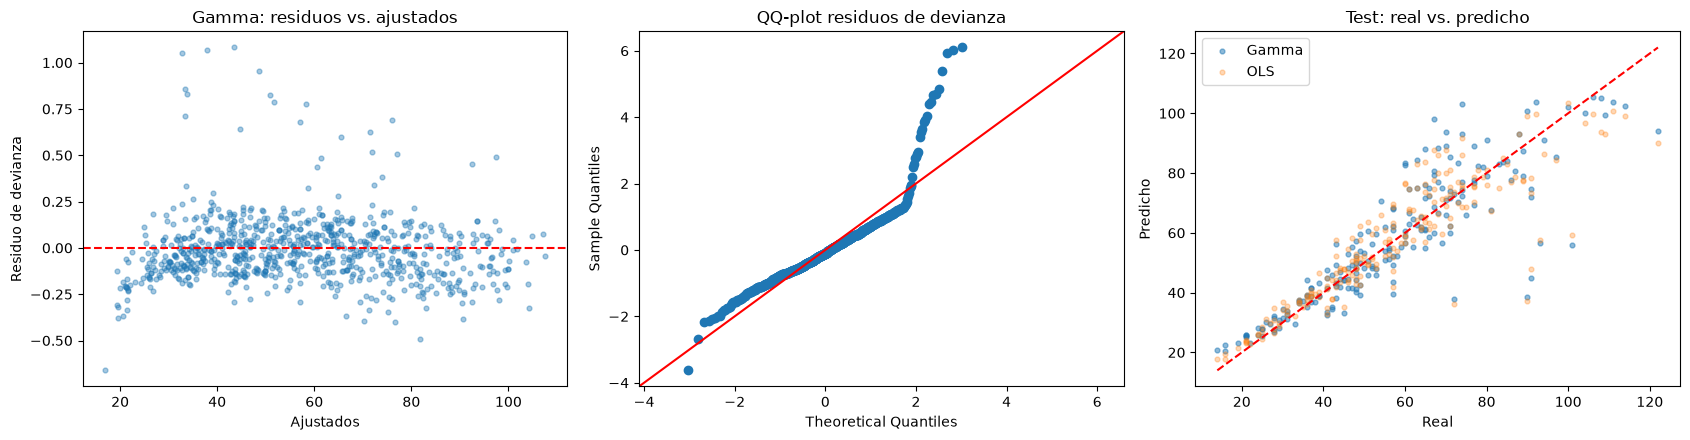

In [12]:
# =========================================================
# Diagnóstico
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].scatter(modelo_gamma.fittedvalues, modelo_gamma.resid_deviance, alpha=0.4, s=12)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Ajustados", ylabel="Residuo de devianza", title="Gamma: residuos vs. ajustados")

sm.qqplot(modelo_gamma.resid_deviance, line="45", fit=True, ax=axes[1])
axes[1].set_title("QQ-plot residuos de devianza")

axes[2].scatter(y_test, pred_gamma, alpha=0.5, s=12, label="Gamma")
axes[2].scatter(y_test, modelo_final.predict(test_imp), alpha=0.3, s=12, label="OLS")
lim = [y_test.min(), y_test.max()]
axes[2].plot(lim, lim, color="red", linestyle="--")
axes[2].set(xlabel="Real", ylabel="Predicho", title="Test: real vs. predicho")
axes[2].legend()
plt.tight_layout()
plt.show()

Los residuos de devianza deben verse como la línea de referencia teórica de una distribución normal estándar:
Si los residuos no caen sobre la diagonal en el QQ-plot, es posible que falten terminos no lineales en el modelo.

## 4. Diagnóstico de residuos: OLS vs. Gamma (forma de embudo)

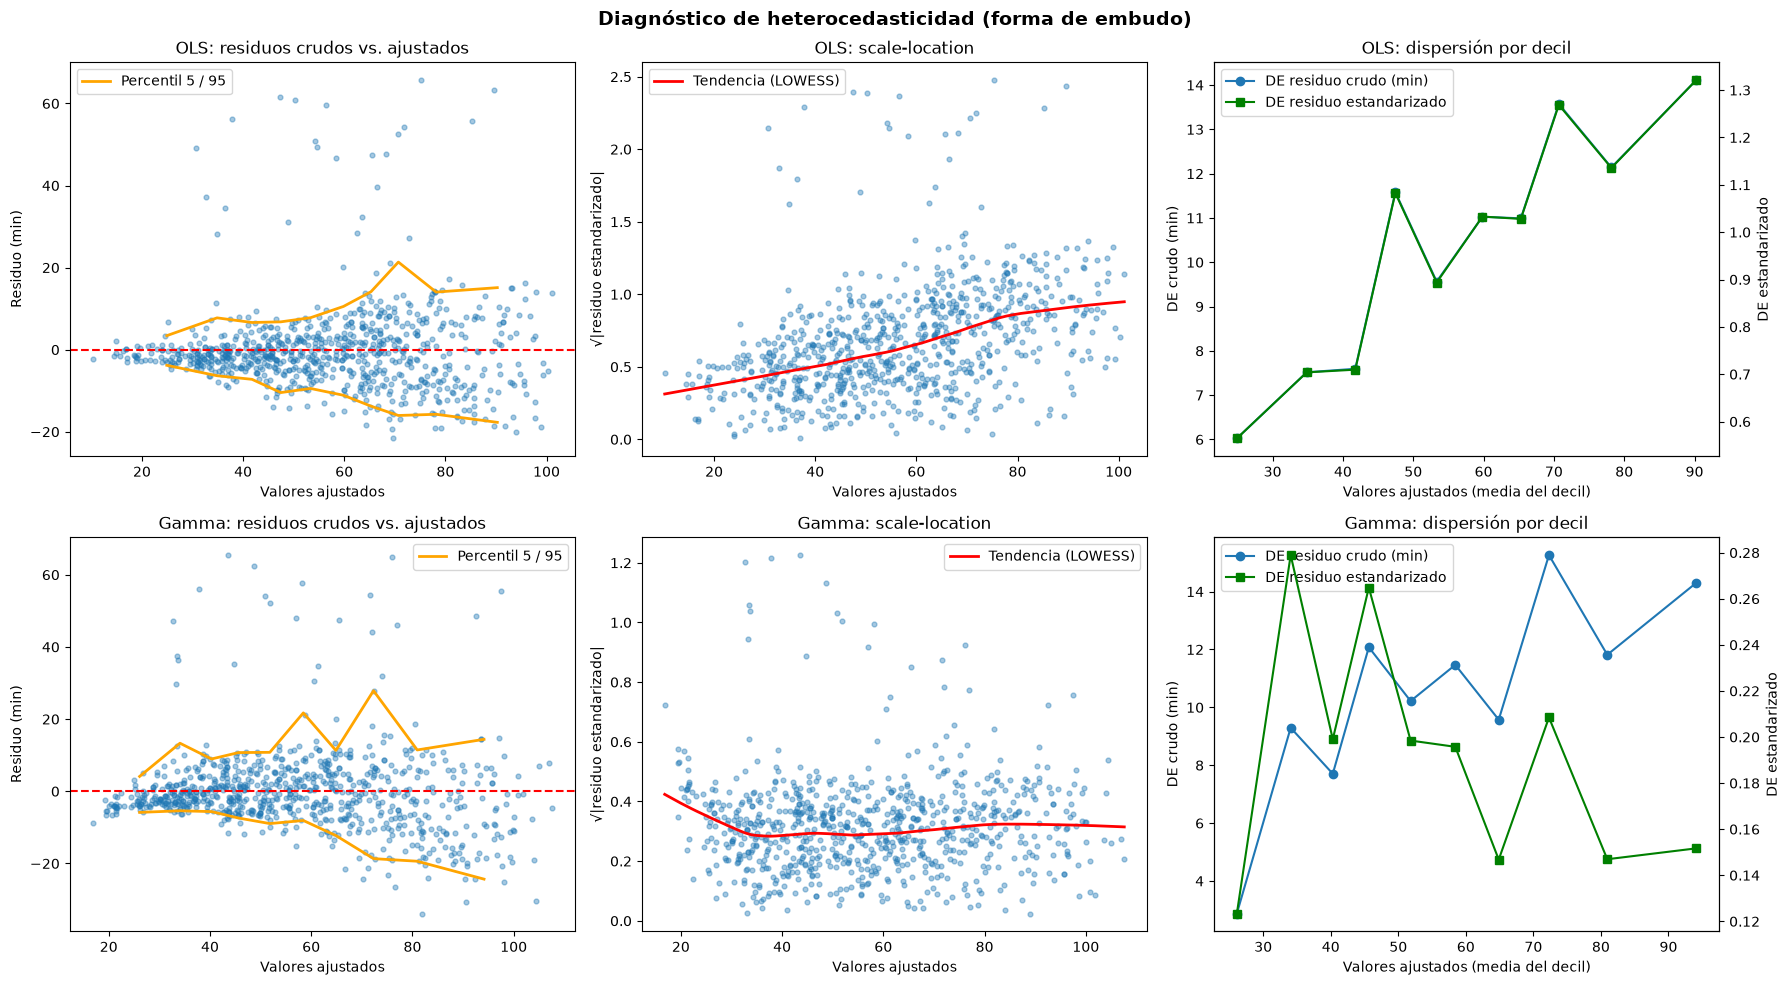

=== Breusch-Pagan (OLS) ===
Estadístico LM = 14.50 | p-valor = 0.1055
-> No hay evidencia de embudo


In [14]:
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan
# Residuos de cada modelo (sobre train)
modelos_res = {
    "OLS": {
        "ajustados": modelo_final.fittedvalues,
        "crudos": modelo_final.resid,                              # y - ŷ
        "estandarizados": modelo_final.get_influence().resid_studentized_internal,
    },
    "Gamma": {
        "ajustados": modelo_gamma.fittedvalues,
        "crudos": modelo_gamma.resid_response,                     # y - ŷ
        "estandarizados": modelo_gamma.resid_pearson,              # (y - ŷ) / sqrt(V(ŷ))
    },
}


def tendencia(x, y):
    """Curva suavizada LOWESS para ver la tendencia."""
    t = lowess(y, x, frac=0.4)
    return t[:, 0], t[:, 1]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for fila, (nombre, r) in enumerate(modelos_res.items()):
    x = np.asarray(r["ajustados"])
    crudos = np.asarray(r["crudos"])
    est = np.asarray(r["estandarizados"])

    # 1. Residuos crudos vs. ajustados
    ax = axes[fila, 0]
    ax.scatter(x, crudos, alpha=0.4, s=12)
    ax.axhline(0, color="red", linestyle="--")
    # bandas: percentiles 5 y 95 por tramo de ajustados (dibujan el "embudo")
    tramos = pd.qcut(x, 10)
    bandas = pd.DataFrame({"x": x, "r": crudos, "t": tramos}).groupby("t", observed=True).agg(
        x=("x", "mean"), p05=("r", lambda s: s.quantile(0.05)), p95=("r", lambda s: s.quantile(0.95)))
    ax.plot(bandas["x"], bandas["p05"], color="orange", lw=2, label="Percentil 5 / 95")
    ax.plot(bandas["x"], bandas["p95"], color="orange", lw=2)
    ax.set(xlabel="Valores ajustados", ylabel="Residuo (min)",
           title=f"{nombre}: residuos crudos vs. ajustados")
    ax.legend()

    # 2. Scale-location: sqrt(|residuo estandarizado|) vs. ajustados
    ax = axes[fila, 1]
    y_sl = np.sqrt(np.abs(est))
    ax.scatter(x, y_sl, alpha=0.4, s=12)
    tx, ty = tendencia(x, y_sl)
    ax.plot(tx, ty, color="red", lw=2, label="Tendencia (LOWESS)")
    ax.set(xlabel="Valores ajustados", ylabel="√|residuo estandarizado|",
           title=f"{nombre}: scale-location")
    ax.legend()

    # 3. Desviación estándar del residuo por decil de ajustados
    ax = axes[fila, 2]
    sd = pd.DataFrame({"t": tramos, "x": x, "crudo": crudos, "est": est}) \
           .groupby("t", observed=True).agg(x=("x", "mean"), sd_crudo=("crudo", "std"),
                                            sd_est=("est", "std"))
    ax.plot(sd["x"], sd["sd_crudo"], marker="o", label="DE residuo crudo (min)")
    ax2 = ax.twinx()
    ax2.plot(sd["x"], sd["sd_est"], marker="s", color="green", label="DE residuo estandarizado")
    ax.set(xlabel="Valores ajustados (media del decil)", ylabel="DE crudo (min)",
           title=f"{nombre}: dispersión por decil")
    ax2.set_ylabel("DE estandarizado")
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left")

plt.suptitle("Diagnóstico de heterocedasticidad (forma de embudo)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

# Prueba formal de Breusch-Pagan (OLS)
# H0: varianza constante (homocedasticidad). p < 0.05 -> hay embudo
lm_stat, lm_p, f_stat, f_p = het_breuschpagan(modelo_final.resid, modelo_final.model.exog)
print("=== Breusch-Pagan (OLS) ===")
print(f"Estadístico LM = {lm_stat:.2f} | p-valor = {lm_p:.4f}")
print("-> Hay heterocedasticidad (embudo)" if lm_p < 0.05 else "-> No hay evidencia de embudo")




## 5. GAM (normal y gamma)
Probar relaciones no lineales en el modelo 

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, operator
from functools import reduce
from pygam import LinearGAM, GammaGAM, s, l, f, te
from sklearn.model_selection import KFold
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error, r2_score)

warnings.filterwarnings("ignore", module="pygam")

# =========================================================
# Matriz de diseño: numéricas + códigos de categóricas + dummies (para 'by')
# =========================================================
niveles = {c: sorted(df[c].dropna().unique()) for c in categoricas}   # niveles fijos

def construir_X(d):
    X = pd.DataFrame(index=d.index)
    for c in numericas:
        X[c] = d[c].astype(float)
    for c in categoricas:
        X[c] = pd.Categorical(d[c], categories=niveles[c]).codes.astype(float)
        for nv in niveles[c][1:]:                       # dummies sin la referencia
            X[f"{c}={nv}"] = (d[c] == nv).astype(float)
    return X

cols_X = construir_X(imputar(train, ajustar_imputador(train))).columns.tolist()
idx = {c: i for i, c in enumerate(cols_X)}

# =========================================================
# Términos
#    lin:var  -> lineal         spl:var -> spline penalizado
#    fac:var  -> factor         by:num*cat -> curva distinta por nivel de cat
#    te:num*num -> superficie suave entre dos numéricas
# =========================================================
N_SPLINES = 10

def termino(clave, lam):
    tipo, vars_ = clave.split(":")
    if tipo == "lin":
        return l(idx[vars_], lam=lam)
    if tipo == "spl":
        return s(idx[vars_], n_splines=N_SPLINES, lam=lam)
    if tipo == "fac":
        return f(idx[vars_], lam=lam)
    a, b = vars_.split("*")
    if tipo == "te":
        return te(idx[a], idx[b], n_splines=[6, 6], lam=lam)
    if tipo == "by":
        return reduce(operator.add, [s(idx[a], by=idx[f"{b}={nv}"], n_splines=8, lam=lam)
                                     for nv in niveles[b][1:]])

interacciones_gam = {
    "by:Distance_km*Traffic_Level":            ("Distance_km", "Traffic_Level"),
    "by:Distance_km*Weather":                  ("Distance_km", "Weather"),
    "by:Distance_km*Vehicle_Type":             ("Distance_km", "Vehicle_Type"),
    "by:Courier_Experience_yrs*Traffic_Level": ("Courier_Experience_yrs", "Traffic_Level"),
    "te:Distance_km*Preparation_Time_min":     ("Distance_km", "Preparation_Time_min"),
}


In [ ]:
# =========================================================
# Ajuste con lambda óptimo por validacion cruzada (GCV) para GAM: lambda determna la curvatura de los splines
# =========================================================
LAMS = np.logspace(-3, 3, 7)

def ajustar_gam(sel, X, y, familia="normal"):
    Clase = LinearGAM if familia == "normal" else GammaGAM
    mejor, mejor_gcv = None, np.inf
    for lam in LAMS:
        terms = reduce(operator.add, [termino(k, lam) for k in sel])
        try:
            gam = Clase(terms, max_iter=200).fit(X, y)
        except Exception:
            continue
        gcv = gam.statistics_["GCV"]
        if gcv < mejor_gcv:
            mejor, mejor_gcv = gam, gcv
            mejor.lam_elegido_ = lam
    if mejor is None:
        raise RuntimeError(f"No se pudo ajustar: {sel}")
    return mejor

In [17]:
# =========================================================
# Evaluación: CV (imputación y lambda dentro de cada fold) + in-sample
# =========================================================
def evaluar_gam(sel, datos, familia="normal", n_splits=5, seed=17):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    mae, rmse, mape, r2 = [], [], [], []

    for idx_tr, idx_va in kf.split(datos):
        tr, va = datos.iloc[idx_tr], datos.iloc[idx_va]
        vals = ajustar_imputador(tr)
        Xtr = construir_X(imputar(tr, vals)).values
        Xva = construir_X(imputar(va, vals)).values
        ytr, yva = tr[target].values, va[target].values

        if sel:
            pred = ajustar_gam(sel, Xtr, ytr, familia).predict(Xva)
        else:
            pred = np.full(len(yva), ytr.mean())

        mae.append(mean_absolute_error(yva, pred))
        rmse.append(np.sqrt(mean_squared_error(yva, pred)))
        mape.append(mean_absolute_percentage_error(yva, pred) * 100)
        r2.append(r2_score(yva, pred))

    res = {"MAE_cv": np.mean(mae), "MAE_sd": np.std(mae),
           "RMSE_cv": np.mean(rmse), "RMSE_sd": np.std(rmse),
           "MAPE_cv": np.mean(mape), "R2_cv": np.mean(r2)}

    if sel:
        full = imputar(datos, ajustar_imputador(datos))
        gam = ajustar_gam(sel, construir_X(full).values, full[target].values, familia)
        st = gam.statistics_
        edof, ll, n = st["edof"], st["loglikelihood"], st["n_samples"]
        res.update({"EDF": edof, "lambda": gam.lam_elegido_, "GCV": st["GCV"],
                    "AIC": st["AIC"], "BIC": -2 * ll + np.log(n) * (edof + 1),
                    "Dev_explicada": st["pseudo_r2"]["explained_deviance"]})
    else:
        res.update({"EDF": 1, "lambda": np.nan, "GCV": np.inf, "AIC": np.inf,
                    "BIC": np.inf, "Dev_explicada": 0.0})
    return res

cols_gam = ["EDF", "lambda", "MAE_cv", "MAE_sd", "RMSE_cv", "RMSE_sd", "MAPE_cv",
            "R2_cv", "Dev_explicada", "GCV", "AIC", "BIC"]

In [18]:
# =========================================================
# Selección forward eligiendo la FORMA de cada variable
# =========================================================
def candidatos(sel):
    forma = {k.split(":")[1]: k.split(":")[0] for k in sel if k[:3] in ("lin", "spl", "fac")}
    cands = []
    for v in numericas:
        if v not in forma:
            cands += [(f"+ lineal({v})", sel + [f"lin:{v}"]),
                      (f"+ spline({v})", sel + [f"spl:{v}"])]
        elif forma[v] == "lin":
            cands.append((f"lineal->spline({v})",
                          [f"spl:{v}" if k == f"lin:{v}" else k for k in sel]))
    for c in categoricas:
        if c not in forma:
            cands.append((f"+ factor({c})", sel + [f"fac:{c}"]))
    for clave, (a, b) in interacciones_gam.items():
        if clave not in sel and a in forma and b in forma:
            cands.append((f"+ {clave}", sel + [clave]))
    return cands

MAYOR_ES_MEJOR = {"R2_cv", "Dev_explicada"}

def seleccion_forward_gam(datos, familia="normal", criterio="RMSE_cv", tol=None):
    if tol is None:   # mejora mínima: evita agregar términos por ruido (igual que model_pipeline)
        tol = 0.01 if criterio in ("RMSE_cv", "MAE_cv", "MAPE_cv") else 0.0
    signo = -1 if criterio in MAYOR_ES_MEJOR else 1
    sel = []
    actual = evaluar_gam(sel, datos, familia)
    hist = [{"paso": 0, "cambio": "(intercepto)", **actual}]

    while True:
        cands = candidatos(sel)
        if not cands:
            break
        res = [(d, nueva, evaluar_gam(nueva, datos, familia)) for d, nueva in cands]
        desc, nueva, mejor = min(res, key=lambda x: signo * x[2][criterio])
        if signo * mejor[criterio] >= signo * actual[criterio] - tol:
            break
        sel, actual = nueva, mejor
        hist.append({"paso": len(hist), "cambio": desc, **mejor})
        print(f"  [{familia} | {criterio}] paso {len(hist)-1}: {desc:45s} {criterio} = {mejor[criterio]:.4f}")

    return sel, pd.DataFrame(hist)

# Esto puede tardar varios minutos (sobre todo la familia gamma)
resultados_gam = {}
for familia in ["normal", "gamma"]:
    for crit in ["RMSE_cv", "BIC"]:
        sel, hist = seleccion_forward_gam(train, familia=familia, criterio=crit)
        resultados_gam[(familia, crit)] = {"terminos": sel, "historial": hist}
        print(f"\n=== GAM {familia} | criterio {crit} ===")
        print(hist[["paso", "cambio"] + cols_gam].round(4).to_string(index=False))
        print(f"Términos: {sel}\n")

resumen_gam = pd.DataFrame({
    f"{fam} | {crit}": {**r["historial"].iloc[-1][cols_gam].to_dict(),
                        "terminos": ", ".join(r["terminos"])}
    for (fam, crit), r in resultados_gam.items()
}).T
print("=== Modelo GAM elegido por cada familia y criterio ===")
print(resumen_gam[cols_gam].astype(float).round(4).to_string())
for k in resumen_gam.index:
    print(f"{k:18s} -> {resumen_gam.loc[k, 'terminos']}")

  [normal | RMSE_cv] paso 1: + lineal(Distance_km)                         RMSE_cv = 13.9178
  [normal | RMSE_cv] paso 2: + spline(Preparation_Time_min)                RMSE_cv = 11.9308
  [normal | RMSE_cv] paso 3: + factor(Traffic_Level)                       RMSE_cv = 11.3540
  [normal | RMSE_cv] paso 4: + factor(Weather)                             RMSE_cv = 10.9561
  [normal | RMSE_cv] paso 5: + lineal(Courier_Experience_yrs)              RMSE_cv = 10.7746

=== GAM normal | criterio RMSE_cv ===
 paso                           cambio     EDF  lambda  MAE_cv  MAE_sd  RMSE_cv  RMSE_sd  MAPE_cv   R2_cv  Dev_explicada      GCV       AIC       BIC
    0                     (intercepto)  1.0000     NaN 17.8851  0.8601  22.1129   1.3880  41.3356 -0.0071         0.0000      inf       inf       inf
    1            + lineal(Distance_km)  1.9996    10.0 10.2387  0.4364  13.9178   0.9349  20.7584  0.5966         0.6072 193.7192 6483.8223 6497.8743
    2   + spline(Preparation_Time_min)  4.4522

In [19]:
# =========================================================
# Modelo GAM final y evaluación en TEST
# =========================================================
familia_final, criterio_final_gam = "gamma", "RMSE_cv"     # Criterio de selección final
terminos_gam = resultados_gam[(familia_final, criterio_final_gam)]["terminos"]

vals = ajustar_imputador(train)
train_imp, test_imp = imputar(train, vals), imputar(test, vals)
X_train_gam, X_test_gam = construir_X(train_imp).values, construir_X(test_imp).values

modelo_gam = ajustar_gam(terminos_gam, X_train_gam, train_imp[target].values, familia_final)
print(f"\nGAM final ({familia_final}, {criterio_final_gam}) | lambda = {modelo_gam.lam_elegido_}")
modelo_gam.summary()

y_test = test_imp[target]
pred_gam = pd.Series(modelo_gam.predict(X_test_gam), index=test_imp.index)

filas = {"GAM": metricas_test(y_test, pred_gam)}
if "modelo_final" in globals(): filas["OLS"] = metricas_test(y_test, modelo_final.predict(test_imp))
if "modelo_gamma" in globals(): filas["GLM Gamma"] = metricas_test(y_test, modelo_gamma.predict(test_imp))
print("\n=== Comparación en TEST ===")
print(pd.DataFrame(filas).T.round(3))


GAM final (gamma, RMSE_cv) | lambda = 100.0
GammaGAM                                                                                                  
=============================================== ==========================================================
Distribution:                         GammaDist Effective DoF:                                     23.1423
Link Function:                          LogLink Log Likelihood:                                 -3314.8215
Number of Samples:                          800 AIC:                                             6677.9275
                                                AICc:                                            6679.4942
                                                GCV:                                                0.0306
                                                Scale:                                               0.195
                                                Pseudo R-Squared:                                  

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15012\3973069022.py:13: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  modelo_gam.summary()


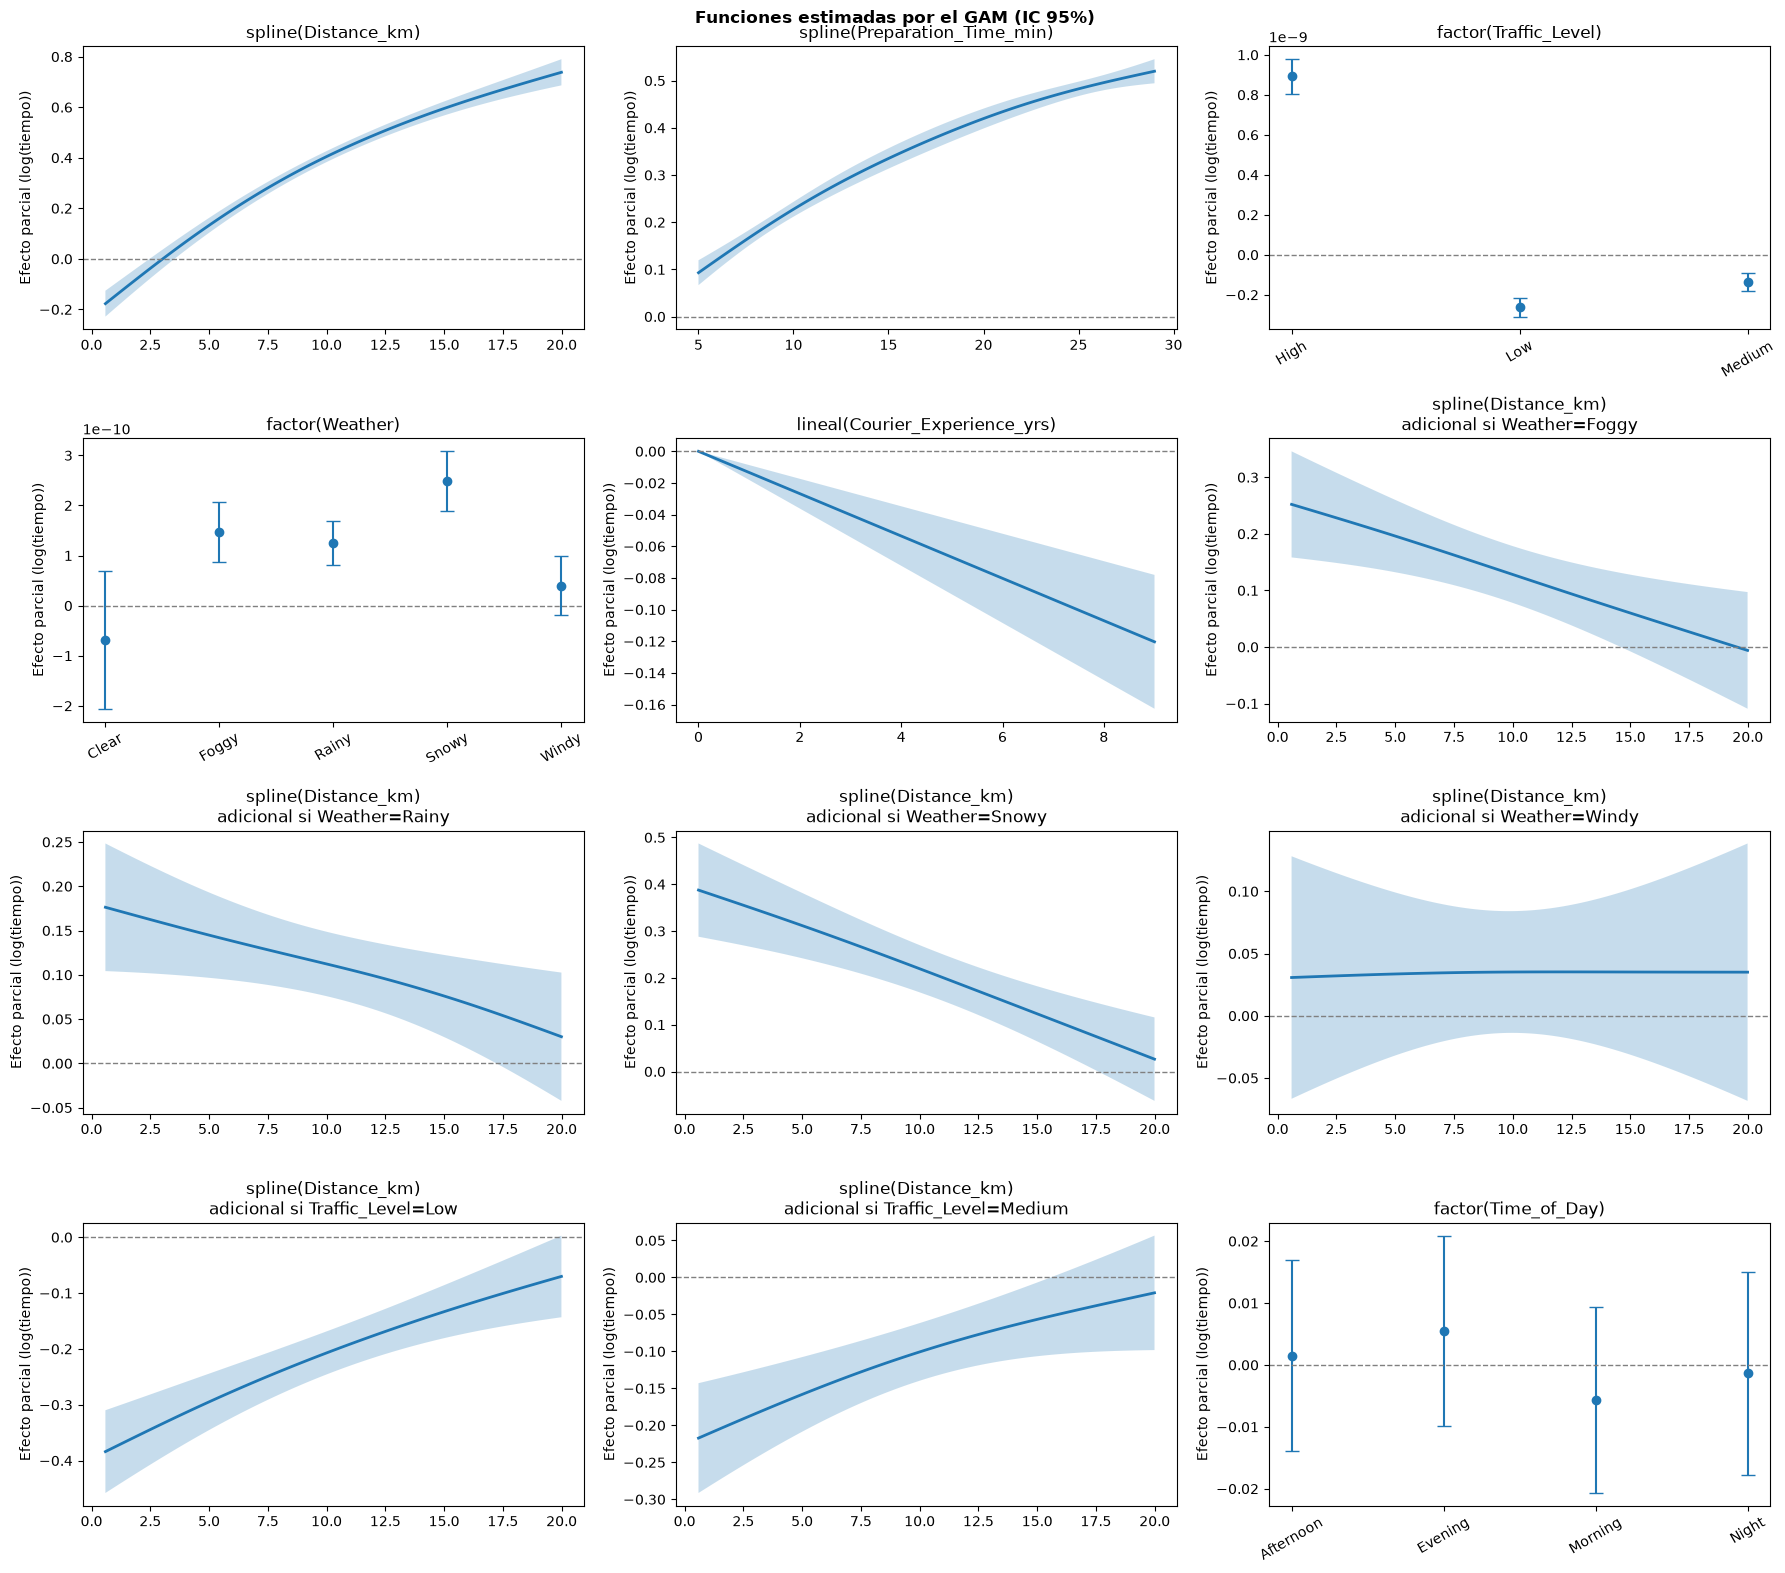

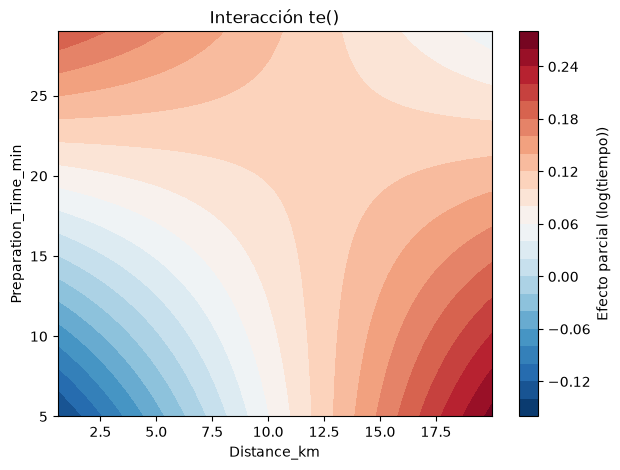

In [20]:
# =========================================================
# 7. Funciones estimadas para cada variable (dependencia parcial)
# =========================================================
def graficar_efectos(gam):
    terms = [(i, t) for i, t in enumerate(gam.terms) if not t.isintercept]
    simples = [(i, t) for i, t in terms if not t.istensor]
    tensores = [(i, t) for i, t in terms if t.istensor]

    ncol = 3
    nrow = int(np.ceil(len(simples) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 4 * nrow), squeeze=False)
    escala = "log(tiempo)" if familia_final == "gamma" else "minutos"

    for ax, (i, t) in zip(axes.flat, simples):
        var = cols_X[t.feature]
        by = getattr(t, "by", None)
        if var in categoricas:                       # factor: un punto por nivel
            k = len(niveles[var])
            XX = np.zeros((k, len(cols_X)))
            XX[:, t.feature] = np.arange(k)
            pdp, ci = gam.partial_dependence(term=i, X=XX, width=0.95)
            ax.errorbar(range(k), pdp, yerr=[pdp - ci[:, 0], ci[:, 1] - pdp], fmt="o", capsize=5)
            ax.set_xticks(range(k))
            ax.set_xticklabels(niveles[var], rotation=30)
            titulo = f"factor({var})"
        else:                                        # lineal o spline
            XX = gam.generate_X_grid(term=i)
            if by is not None:
                XX[:, by] = 1
            pdp, ci = gam.partial_dependence(term=i, X=XX, width=0.95)
            x = XX[:, t.feature]
            ax.plot(x, pdp, lw=2)
            ax.fill_between(x, ci[:, 0], ci[:, 1], alpha=0.25)
            tipo = "spline" if t.__class__.__name__ == "SplineTerm" else "lineal"
            titulo = f"{tipo}({var})" + (f"\nadicional si {cols_X[by]}" if by is not None else "")
        ax.axhline(0, color="gray", linestyle="--", lw=1)
        ax.set(title=titulo, ylabel=f"Efecto parcial ({escala})")

    for ax in axes.flat[len(simples):]:
        ax.axis("off")
    plt.suptitle("Funciones estimadas por el GAM (IC 95%)", fontweight="bold")
    plt.tight_layout()
    plt.show()

    for i, t in tensores:                            # superficies te(num, num)
        XX = gam.generate_X_grid(term=i, meshgrid=True)
        Z = gam.partial_dependence(term=i, X=XX, meshgrid=True)
        plt.figure(figsize=(7, 5))
        cs = plt.contourf(XX[0], XX[1], Z, levels=20, cmap="RdBu_r")
        plt.colorbar(cs, label=f"Efecto parcial ({escala})")
        plt.xlabel(cols_X[t.feature[0]])
        plt.ylabel(cols_X[t.feature[1]])
        plt.title("Interacción te()")
        plt.show()

graficar_efectos(modelo_gam)



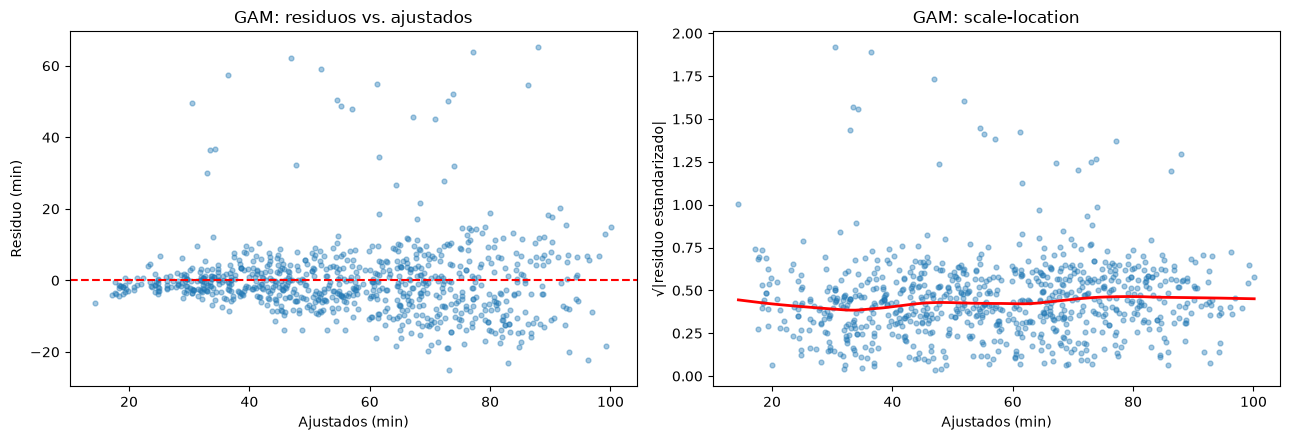

In [21]:
# =========================================================
# 8. Residuos (embudo)
# =========================================================
y_tr = train_imp[target].values
ajust = modelo_gam.predict(X_train_gam)
resid = y_tr - ajust
# Normal: varianza constante | Gamma: varianza ∝ mu² -> residuo de Pearson = (y - mu) / mu
resid_est = resid / np.sqrt(modelo_gam.statistics_["scale"]) if familia_final == "normal" \
            else resid / ajust / np.sqrt(modelo_gam.statistics_["scale"])

from statsmodels.nonparametric.smoothers_lowess import lowess
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(ajust, resid, alpha=0.4, s=12)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Ajustados (min)", ylabel="Residuo (min)", title="GAM: residuos vs. ajustados")
y_sl = np.sqrt(np.abs(resid_est))
axes[1].scatter(ajust, y_sl, alpha=0.4, s=12)
tl = lowess(y_sl, ajust, frac=0.4)
axes[1].plot(tl[:, 0], tl[:, 1], color="red", lw=2)
axes[1].set(xlabel="Ajustados (min)", ylabel="√|residuo estandarizado|", title="GAM: scale-location")
plt.tight_layout()
plt.show()

## 6. Machine learning: ElasticNet, Random Forest y Gradient Boosting

Exploración de modelos de machine learning para ver si mejora la capacidad predictiva

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

features = numericas + categoricas
X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

# =========================================================
# Preprocesamiento (la imputación se aprende dentro de cada fold)
# =========================================================
# ElasticNet y Random Forest: imputar + escalar + one-hot
prep_ohe = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), numericas),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), categoricas),
])

# HistGradientBoosting: maneja los NaN de forma nativa y las categóricas sin one-hot
prep_hgb = ColumnTransformer([
    ("num", "passthrough", numericas),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categoricas),
])
cat_idx = list(range(len(numericas), len(features)))      # posiciones de las categóricas

# =========================================================
# Modelos y espacios de búsqueda de hiperparámetros
# =========================================================
params_hgb = {
    "modelo__learning_rate": loguniform(0.01, 0.3),
    "modelo__max_leaf_nodes": randint(4, 40),
    "modelo__max_depth": [None, 2, 3, 4, 6],
    "modelo__min_samples_leaf": randint(10, 80),
    "modelo__l2_regularization": loguniform(1e-3, 10),
}

def hgb(loss):
    return HistGradientBoostingRegressor(
        loss=loss, categorical_features=cat_idx, max_iter=1000,
        early_stopping=True, validation_fraction=0.15, n_iter_no_change=20, random_state=17)

modelos_ml = {
    "ElasticNet": (
        Pipeline([("prep", prep_ohe), ("modelo", ElasticNet(max_iter=20000))]),
        {"modelo__alpha": loguniform(1e-3, 10), "modelo__l1_ratio": uniform(0, 1)},
    ),
    "RandomForest": (
        Pipeline([("prep", prep_ohe),
                  ("modelo", RandomForestRegressor(n_estimators=400, random_state=17, n_jobs=1))]),
        {"modelo__max_depth": [None, 4, 6, 8, 12],
         "modelo__min_samples_leaf": randint(1, 30),
         "modelo__max_features": [1.0, 0.7, 0.5, "sqrt"]},
    ),
    "HGB (cuadrática)": (Pipeline([("prep", prep_hgb), ("modelo", hgb("squared_error"))]), params_hgb),
    "HGB (gamma)":      (Pipeline([("prep", prep_hgb), ("modelo", hgb("gamma"))]), params_hgb),
}

# =========================================================
# Validación cruzada anidada
#    - interna (5 folds): elige hiperparámetros
#    - externa (5 folds): estima el error del proceso completo sin sesgo
# =========================================================
scoring = {"MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error",
           "MAPE": "neg_mean_absolute_percentage_error",
           "R2": "r2"}

cv_interna = KFold(n_splits=5, shuffle=True, random_state=17)
cv_externa = KFold(n_splits=5, shuffle=True, random_state=17)
N_ITER = 25                     # combinaciones de hiperparámetros a probar por modelo

resultados_cv, busquedas = {}, {}

for nombre, (pipe, params) in modelos_ml.items():
    print(f"Ajustando {nombre}...")
    busqueda = RandomizedSearchCV(pipe, params, n_iter=N_ITER, scoring=scoring, refit="RMSE",
                                  cv=cv_interna, random_state=17, n_jobs=-1)

    cv = cross_validate(busqueda, X_train, y_train, cv=cv_externa, scoring=scoring)
    resultados_cv[nombre] = {
        "MAE_cv": -cv["test_MAE"].mean(),   "MAE_sd": cv["test_MAE"].std(),
        "RMSE_cv": -cv["test_RMSE"].mean(), "RMSE_sd": cv["test_RMSE"].std(),
        "MAPE_cv": -cv["test_MAPE"].mean() * 100,
        "R2_cv": cv["test_R2"].mean(),
    }

    busqueda.fit(X_train, y_train)          # ajuste final con todo train
    busquedas[nombre] = busqueda

tabla_cv = pd.DataFrame(resultados_cv).T.sort_values("RMSE_cv")
print("\n=== Validación cruzada anidada (train) ===")
print(tabla_cv.round(3))

print("\n=== Mejores hiperparámetros ===")
for nombre, b in busquedas.items():
    print(f"{nombre}: { {k.replace('modelo__', ''): (round(v, 4) if isinstance(v, float) else v)
                         for k, v in b.best_params_.items()} }")



Ajustando ElasticNet...
Ajustando RandomForest...
Ajustando HGB (cuadrática)...
Ajustando HGB (gamma)...

=== Validación cruzada anidada (train) ===
                  MAE_cv  MAE_sd  RMSE_cv  RMSE_sd  MAPE_cv  R2_cv
ElasticNet         6.697   0.557   10.793    1.233   11.256  0.757
HGB (gamma)        7.253   0.600   11.228    1.239   12.507  0.738
HGB (cuadrática)   7.383   0.467   11.310    1.106   12.899  0.734
RandomForest       7.653   0.512   11.587    1.123   14.256  0.721

=== Mejores hiperparámetros ===
ElasticNet: {'alpha': np.float64(0.0384), 'l1_ratio': np.float64(0.7887)}
RandomForest: {'max_depth': 6, 'max_features': 0.5, 'min_samples_leaf': 4}
HGB (cuadrática): {'l2_regularization': np.float64(0.4375), 'learning_rate': np.float64(0.0727), 'max_depth': 2, 'max_leaf_nodes': 6, 'min_samples_leaf': 28}
HGB (gamma): {'l2_regularization': np.float64(0.422), 'learning_rate': np.float64(0.0874), 'max_depth': 2, 'max_leaf_nodes': 21, 'min_samples_leaf': 51}


In [23]:
# =========================================================
# Comparación en TEST con TODOS los modelos
# =========================================================
filas = {nombre: metricas_test(y_test, pd.Series(b.predict(X_test), index=y_test.index))
         for nombre, b in busquedas.items()}

# Modelos estadísticos anteriores (si existen en la sesión)
vals = ajustar_imputador(train)
test_imp = imputar(test, vals)
if "modelo_final" in globals(): filas["OLS"] = metricas_test(y_test, modelo_final.predict(test_imp))
if "modelo_gamma" in globals(): filas["GLM Gamma"] = metricas_test(y_test, modelo_gamma.predict(test_imp))
if "modelo_gam" in globals():   filas["GAM"] = metricas_test(y_test, modelo_gam.predict(construir_X(test_imp).values))

comparacion_final = pd.DataFrame(filas).T.sort_values("RMSE")
print("\n=== Comparación final en TEST (menor MAE/RMSE = mejor) ===")
print(comparacion_final.round(3))


=== Comparación final en TEST (menor MAE/RMSE = mejor) ===
                    MAE    RMSE  MAPE_%     R2  Pred_min
OLS               6.408   9.985  10.700  0.790    17.770
ElasticNet        6.482  10.061  10.955  0.786    17.787
GAM               6.658  10.431  11.057  0.770    18.244
HGB (cuadrática)  7.068  10.633  12.455  0.761    17.650
HGB (gamma)       7.105  10.690  12.306  0.759    19.402
GLM Gamma         7.045  10.839  12.240  0.752    20.508
RandomForest      7.504  10.941  13.897  0.747    23.552



Mejor modelo ML (por RMSE_cv): ElasticNet


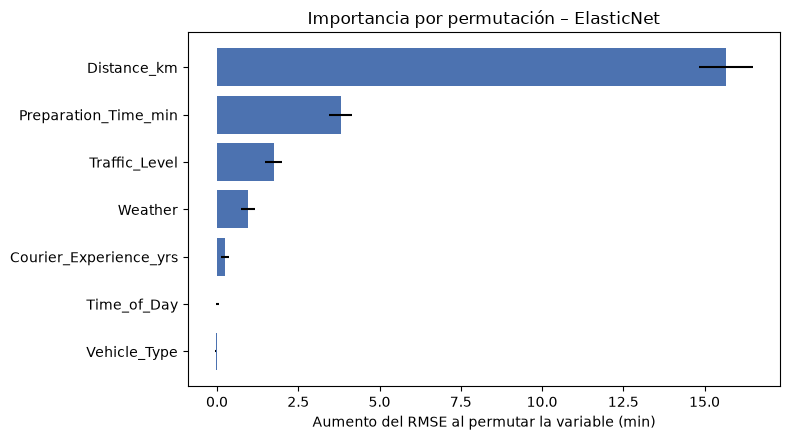

In [24]:
# =========================================================
# Interpretación del mejor modelo de ML
# =========================================================
mejor_ml = tabla_cv.index[0]
modelo_ml = busquedas[mejor_ml].best_estimator_
print(f"\nMejor modelo ML (por RMSE_cv): {mejor_ml}")

# 5a. Importancia por permutación (en test)
imp = permutation_importance(modelo_ml, X_test, y_test, n_repeats=30, random_state=17,
                             scoring="neg_root_mean_squared_error")
importancia = pd.DataFrame({"importancia": imp.importances_mean, "sd": imp.importances_std},
                           index=features).sort_values("importancia")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importancia.index, importancia["importancia"], xerr=importancia["sd"], color="#4C72B0")
ax.set(xlabel="Aumento del RMSE al permutar la variable (min)",
       title=f"Importancia por permutación – {mejor_ml}")
plt.tight_layout()
plt.show()

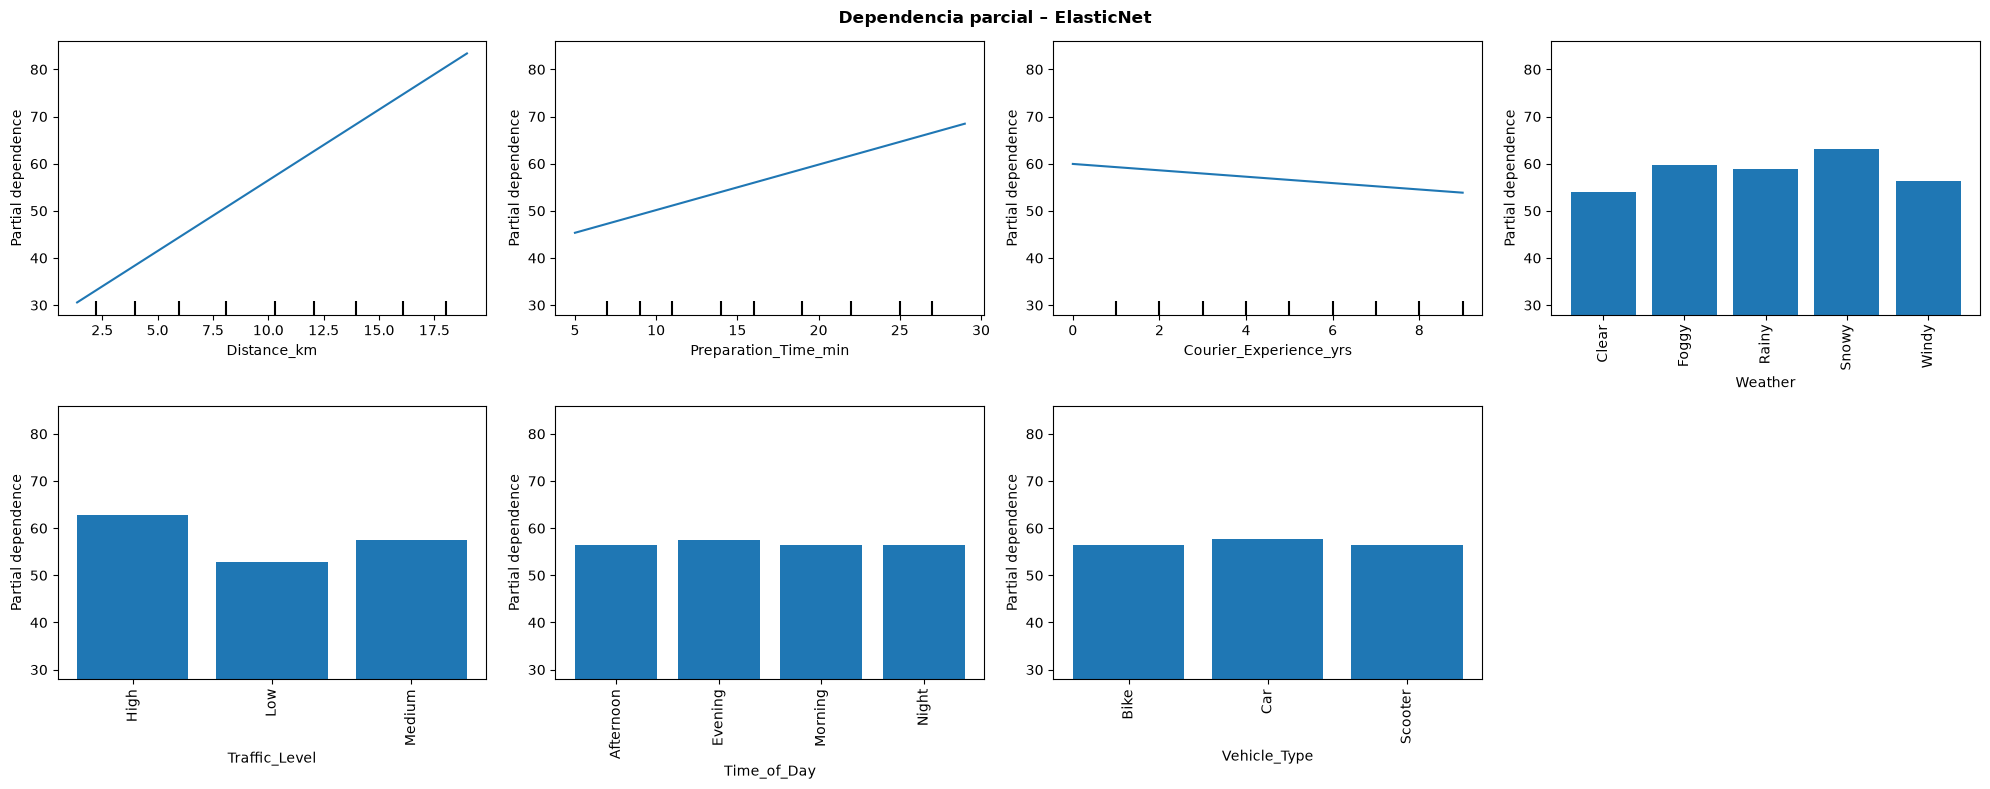

In [25]:
# Dependencia parcial (forma del efecto de cada variable)
X_pdp = X_train.dropna().astype({c: float for c in numericas})

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
PartialDependenceDisplay.from_estimator(
    modelo_ml, X_pdp, features=features, categorical_features=categoricas,
    kind="average", ax=axes.ravel()[:len(features)])
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
plt.suptitle(f"Dependencia parcial – {mejor_ml}", fontweight="bold")
plt.tight_layout()
plt.show()

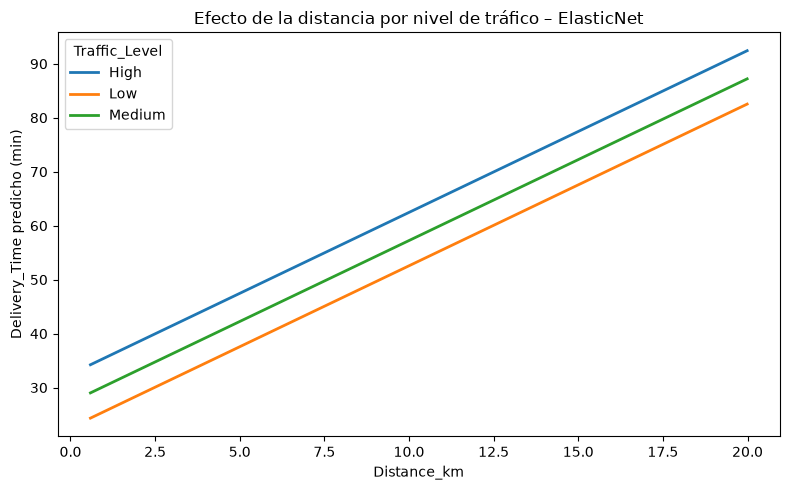

In [26]:
# Interacción Distancia × Tráfico
fig, ax = plt.subplots(figsize=(8, 5))
for nivel in sorted(X_pdp["Traffic_Level"].unique()):
    Xn = X_pdp.copy()
    Xn["Traffic_Level"] = nivel
    grid = np.linspace(X_pdp["Distance_km"].min(), X_pdp["Distance_km"].max(), 40)
    medias = []
    for g in grid:
        Xn["Distance_km"] = g
        medias.append(modelo_ml.predict(Xn).mean())
    ax.plot(grid, medias, lw=2, label=nivel)
ax.set(xlabel="Distance_km", ylabel="Delivery_Time predicho (min)",
       title=f"Efecto de la distancia por nivel de tráfico – {mejor_ml}")
ax.legend(title="Traffic_Level")
plt.tight_layout()
plt.show()

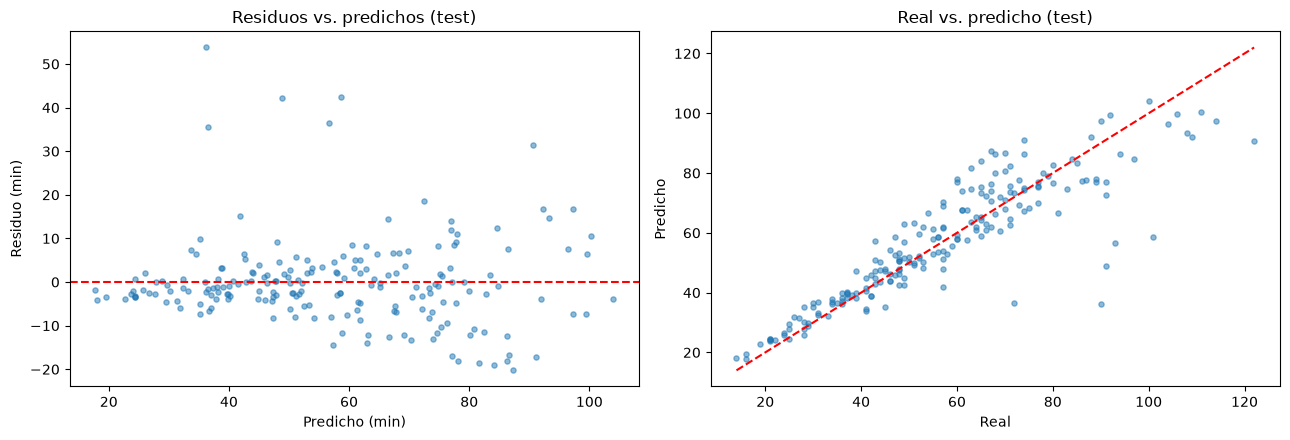

In [27]:
# Residuos en test
pred = modelo_ml.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(pred, y_test - pred, alpha=0.5, s=14)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Predicho (min)", ylabel="Residuo (min)", title="Residuos vs. predichos (test)")
axes[1].scatter(y_test, pred, alpha=0.5, s=14)
lim = [y_test.min(), y_test.max()]
axes[1].plot(lim, lim, color="red", linestyle="--")
axes[1].set(xlabel="Real", ylabel="Predicho", title="Real vs. predicho (test)")
plt.tight_layout()
plt.show()

## 7. Comparación final y elección del modelo

### Bootstrap pareado en test: ¿la diferencia con el OLS es real?

Ver si la diferencia entre rmse glm y rmse ols es significativa: Toma 2000 muetsras de test distintas (cada una con 200 registros), hace la diferencia entre los rmse, ordena las dfiferencias y toma como intervalo de confianza el percentil 2,5 y el 97,5

Si:

- Todo por encima de 0: El competidor tiene más error en casi todas las muestras posibles: el OLS es mejor de verdad 
- Contiene el 0: No hay diferencia significativa: empatan                                                     
- Todo por debajo de 0: El competidor es mejor

In [28]:
def bootstrap_diferencia(y, pred_a, pred_b, n=2000, seed=17):
    """IC 95% de RMSE(B) - RMSE(A). Si incluye 0 -> no hay diferencia real."""
    rng = np.random.default_rng(seed)
    y, pa, pb = map(np.asarray, (y, pred_a, pred_b))
    difs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        rmse_a = np.sqrt(np.mean((y[i] - pa[i]) ** 2))
        rmse_b = np.sqrt(np.mean((y[i] - pb[i]) ** 2))
        difs.append(rmse_b - rmse_a)
    return np.percentile(difs, [2.5, 50, 97.5])

pred_ols = modelo_final.predict(test_imp)
competidores = {"GLM Gamma": modelo_gamma.predict(test_imp)}
if "busquedas" in globals():
    competidores["HGB (gamma)"] = busquedas["HGB (gamma)"].predict(X_test)

for nombre, pred in competidores.items():
    inf, med, sup = bootstrap_diferencia(y_test, pred_ols, pred)
    print(f"RMSE({nombre}) - RMSE(OLS): {med:.3f}  IC95% [{inf:.3f}, {sup:.3f}]",
          "-> OLS es mejor" if inf > 0 else "-> no hay diferencia significativa")

RMSE(GLM Gamma) - RMSE(OLS): 0.868  IC95% [0.353, 1.459] -> OLS es mejor
RMSE(HGB (gamma)) - RMSE(OLS): 0.711  IC95% [0.146, 1.301] -> OLS es mejor


### Confirmación con validación cruzada en train

In [29]:
cv_ols = evaluar(terminos_finales, train)
cv_gamma = evaluar_gamma(terminos_gamma, train)
print(f"RMSE_cv OLS   = {cv_ols['RMSE_cv']:.3f} ± {cv_ols['RMSE_sd']:.3f}")
print(f"RMSE_cv Gamma = {cv_gamma['RMSE_cv']:.3f} ± {cv_gamma['RMSE_sd']:.3f}")
print(tabla_cv[["RMSE_cv", "RMSE_sd"]].round(3))    # modelos de ML

RMSE_cv OLS   = 10.680 ± 1.970
RMSE_cv Gamma = 11.324 ± 1.977
                  RMSE_cv  RMSE_sd
ElasticNet         10.793    1.233
HGB (gamma)        11.228    1.239
HGB (cuadrática)   11.310    1.106
RandomForest       11.587    1.123


### Error del OLS según la duración predicha

Dado que hay más varianza cuando la media de entrega es mayor, se observa cual sería el error del modelo de acuerdo a la duración de la entrega predicha

            n  pred_media   MAE   RMSE  MAPE_pct
tramo                                           
Q1 cortos  50       31.94  4.49   9.65     11.56
Q2         50       48.59  4.13   7.47      7.63
Q3         50       64.42  7.23  10.58     11.05
Q4 largos  50       83.44  9.79  11.74     12.56


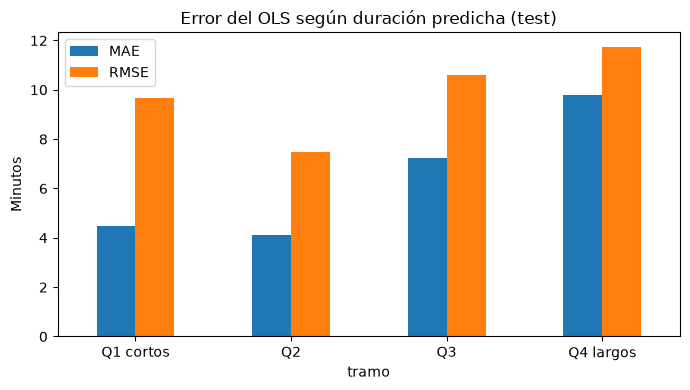

In [30]:
pred_ols = modelo_final.predict(test_imp)
err = y_test - pred_ols

tramos = pd.qcut(pred_ols, 4, labels=["Q1 cortos", "Q2", "Q3", "Q4 largos"])
por_tramo = pd.DataFrame({"pred": pred_ols, "real": y_test, "err": err, "tramo": tramos}) \
    .groupby("tramo", observed=True).agg(
        n=("err", "size"),
        pred_media=("pred", "mean"),
        MAE=("err", lambda e: e.abs().mean()),
        RMSE=("err", lambda e: np.sqrt((e ** 2).mean())),
        MAPE_pct=("err", lambda e: (e.abs() / y_test.loc[e.index]).mean() * 100),
    )
print(por_tramo.round(2))

por_tramo[["MAE", "RMSE"]].plot(kind="bar", figsize=(7, 4), rot=0,
                                title="Error del OLS según duración predicha (test)")
plt.ylabel("Minutos")
plt.tight_layout()
plt.show()

**Decisión:** se elige el **OLS** (fórmula de la selección forward con criterio `RMSE_cv`). Se ajusta con todos los datos en `predictive_model.ipynb`.